In [23]:
raw_df = pd.read_csv("../data/raw/logistics_data.csv")

print("Rows:", raw_df.shape[0])
print("Columns:", raw_df.shape[1])
print("Shape:", raw_df.shape)

Rows: 5000
Columns: 22
Shape: (5000, 22)


In [1]:
# Logistics Delivery Performance & Cost Analytics
# Exploratory Data Analysis

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project path
PROJECT_ROOT = Path.cwd().parent

# Cleaned dataset path
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "logistics_cleaned.csv"
)

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

df.head()

,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,...,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag,delivery_days,delay_days,cost_per_km,total_logistics_cost,on_time_flag
0,ORD101253,CUST12780,2025-03-12,Bengaluru,Bengaluru,Chennai,451.7,Home & Kitchen,7,5.51,...,2025-03-24,Delayed,3.0,0,0,10,5,4.526367,2426.22,0
1,ORD102838,CUST11842,2025-12-02,Delhi,Delhi,Surat,592.8,Automotive,1,1.05,...,2025-12-12,Delivered,4.0,0,0,7,0,4.356781,2967.72,1
2,ORD103457,CUST10940,2025-04-21,Pune,Pune,Nagpur,191.9,Clothing,3,9.09,...,2025-04-28,Delivered,5.0,0,0,5,0,4.258624,1003.06,1
3,ORD100061,CUST10263,2025-02-21,Pune,Pune,Coimbatore,376.4,Clothing,7,1.34,...,2025-03-04,Delayed,3.0,0,0,8,2,4.551594,2099.57,0
4,ORD103947,CUST12467,2025-08-22,Mumbai,Mumbai,Delhi,895.3,Sports,5,3.95,...,2025-08-30,Delivered,4.0,0,0,6,0,4.445504,4970.48,1


In [2]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (4963, 27)

Column Names:
['order_id', 'customer_id', 'order_date', 'warehouse', 'origin_city', 'destination_city', 'distance_km', 'product_category', 'quantity', 'weight_kg', 'shipping_mode', 'delivery_partner', 'shipping_cost', 'fuel_cost', 'warehouse_processing_hours', 'dispatch_date', 'expected_delivery_date', 'actual_delivery_date', 'delivery_status', 'customer_rating', 'damage_flag', 'return_flag', 'delivery_days', 'delay_days', 'cost_per_km', 'total_logistics_cost', 'on_time_flag']

Data Types:
order_id                          str
customer_id                       str
order_date                        str
warehouse                         str
origin_city                       str
destination_city                  str
distance_km                   float64
product_category                  str
quantity                        int64
weight_kg                     float64
shipping_mode                     str
delivery_partner                  str
shipping_cost         

In [3]:
# Missing value analysis

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Missing Values:")
print(missing_values)

Missing Values:
Series([], dtype: int64)


In [4]:
# Descriptive statistics

df.describe().T

,count,mean,std,min,25%,50%,75%,max
distance_km,4963.0,411.327624,260.402516,28.800000,221.900000,354.200000,541.900000,1800.000000
quantity,4963.0,3.974612,2.007081,1.000000,2.000000,4.000000,6.000000,7.000000
weight_kg,4963.0,5.528404,3.921414,0.200000,2.700000,4.630000,7.425000,34.090000
shipping_cost,4963.0,2281.888892,1673.275986,121.540000,1146.805000,1808.200000,2894.670000,16275.330000
fuel_cost,4963.0,372.455453,245.431503,20.000000,195.615000,319.115000,493.655000,1755.710000
warehouse_processing_hours,4963.0,8.390387,2.295827,2.000000,6.825000,8.380000,10.000000,15.650000
customer_rating,4963.0,4.122507,0.706039,2.000000,4.000000,4.000000,5.000000,5.000000
damage_flag,4963.0,0.028612,0.166729,0.000000,0.000000,0.000000,0.000000,1.000000
return_flag,4963.0,0.043321,0.203598,0.000000,0.000000,0.000000,0.000000,1.000000
delivery_days,4963.0,5.625630,2.253056,1.000000,4.000000,5.000000,7.000000,15.000000


In [5]:
# Categorical data analysis

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print("-" * 40)
    print(df[column].value_counts().head(10))


order_id
----------------------------------------
order_id
ORD101253    1
ORD102838    1
ORD103457    1
ORD100061    1
ORD103947    1
ORD102587    1
ORD104185    1
ORD103311    1
ORD100567    1
ORD104497    1
Name: count, dtype: int64

customer_id
----------------------------------------
customer_id
CUST11656    10
CUST12008     8
CUST12190     7
CUST10715     7
CUST10051     7
CUST12518     7
CUST11200     7
CUST10004     7
CUST10036     6
CUST10775     6
Name: count, dtype: int64

order_date
----------------------------------------
order_date
2025-12-15    24
2025-02-21    23
2025-09-06    22
2025-05-28    22
2025-08-23    22
2025-04-21    21
2025-03-08    21
2025-02-15    21
2025-05-03    21
2025-08-11    20
Name: count, dtype: int64

warehouse
----------------------------------------
warehouse
Hyderabad    1084
Bengaluru     882
Pune          789
Chennai       765
Mumbai        738
Delhi         705
Name: count, dtype: int64

origin_city
----------------------------------------
or

C:\Users\janga\AppData\Local\Temp\ipykernel_19620\2753788851.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [6]:
# Delivery status percentage

status_percentage = df["delivery_status"].value_counts(normalize=True) * 100

print(status_percentage)

delivery_status
Delivered    76.062865
Delayed      23.937135
Name: proportion, dtype: float64


In [7]:
# Shipping mode analysis

shipping_mode_counts = df["shipping_mode"].value_counts()

print(shipping_mode_counts)

shipping_mode
Road       2513
Rail        928
Air         910
Express     612
Name: count, dtype: int64


In [8]:
# Delivery partner analysis

partner_counts = df["delivery_partner"].value_counts()

print(partner_counts)

delivery_partner
Ecom Express    850
Xpressbees      842
Shadowfax       840
Delhivery       829
Dtdc            807
Blue Dart       795
Name: count, dtype: int64


In [9]:
# Product category analysis

category_counts = df["product_category"].value_counts()

print(category_counts)

product_category
Books             663
Electronics       644
Sports            641
Home & Kitchen    640
Automotive        621
Beauty            616
Clothing          576
Grocery           562
Name: count, dtype: int64


In [10]:
# Average delivery time by shipping mode

avg_delivery_by_mode = (
    df.groupby("shipping_mode")["delivery_days"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_delivery_by_mode)

shipping_mode
Rail       7.206897
Road       6.156387
Express    4.246732
Air        3.474725
Name: delivery_days, dtype: float64


In [11]:
# Average shipping cost by shipping mode

avg_cost_by_mode = (
    df.groupby("shipping_mode")["shipping_cost"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_cost_by_mode)

shipping_mode
Air        3778.564473
Express    3080.692173
Road       1844.382447
Rail       1472.202802
Name: shipping_cost, dtype: float64


In [12]:
# Average delay by shipping mode

avg_delay_by_mode = (
    df.groupby("shipping_mode")["delay_days"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_delay_by_mode)

shipping_mode
Rail       0.812500
Road       0.753681
Air        0.574725
Express    0.535948
Name: delay_days, dtype: float64


In [17]:
# Average delivery time by product category

avg_delivery_by_category = (
    df.groupby("product_category")["delivery_days"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_delivery_by_category)

product_category
Beauty            5.740260
Sports            5.709828
Grocery           5.688612
Electronics       5.680124
Automotive        5.624799
Books             5.607843
Clothing          5.498264
Home & Kitchen    5.454688
Name: delivery_days, dtype: float64


In [18]:

# Average logistics cost by product category

avg_cost_by_category = (
    df.groupby("product_category")["total_logistics_cost"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_cost_by_category)

product_category
Sports            2794.170187
Automotive        2731.410910
Books             2683.795928
Beauty            2627.969570
Clothing          2618.921997
Home & Kitchen    2594.030469
Electronics       2587.613284
Grocery           2585.327829
Name: total_logistics_cost, dtype: float64


In [19]:
# On-time delivery percentage by shipping mode

on_time_by_mode = (
    df.groupby("shipping_mode")["on_time_flag"]
    .mean() * 100
)

print(on_time_by_mode)

shipping_mode
Air        80.769231
Express    82.516340
Rail       71.875000
Road       74.333466
Name: on_time_flag, dtype: float64


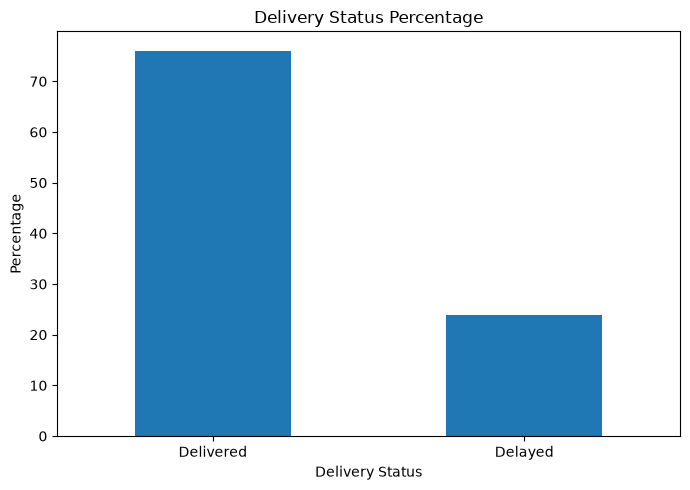

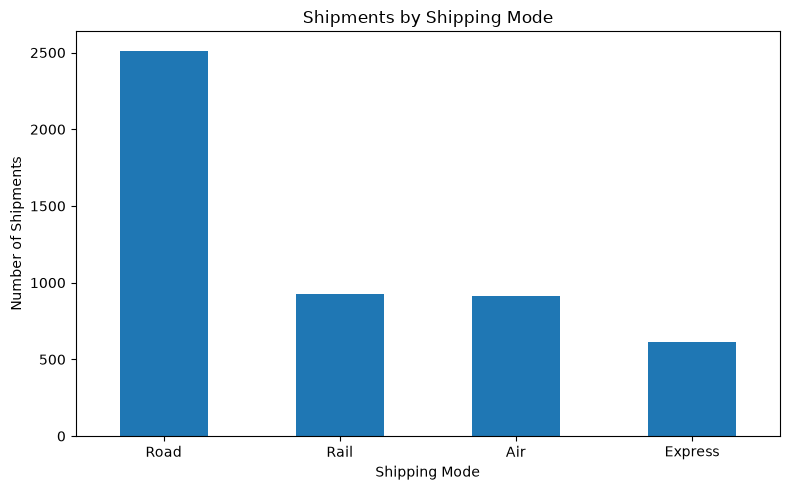

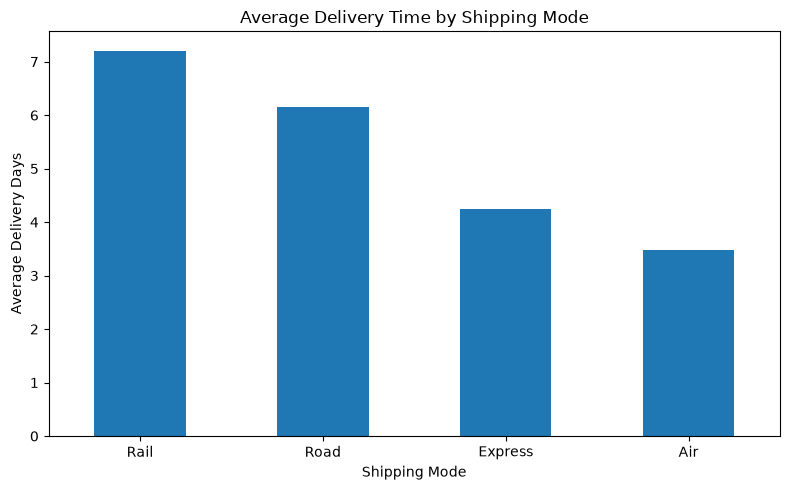

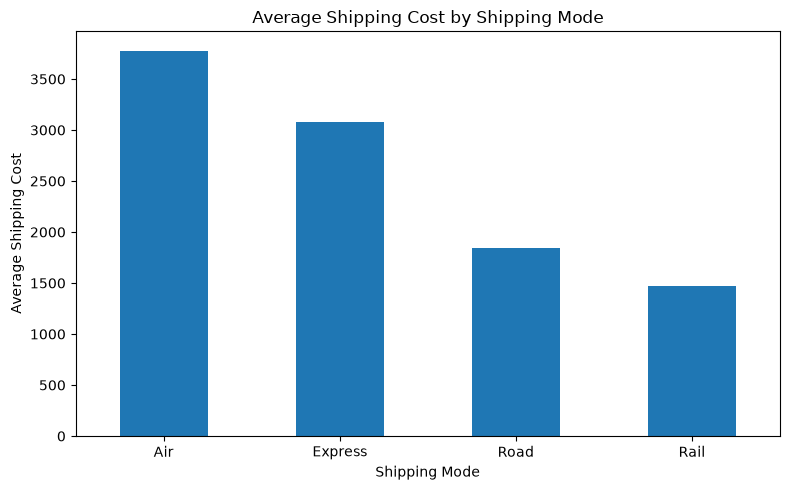

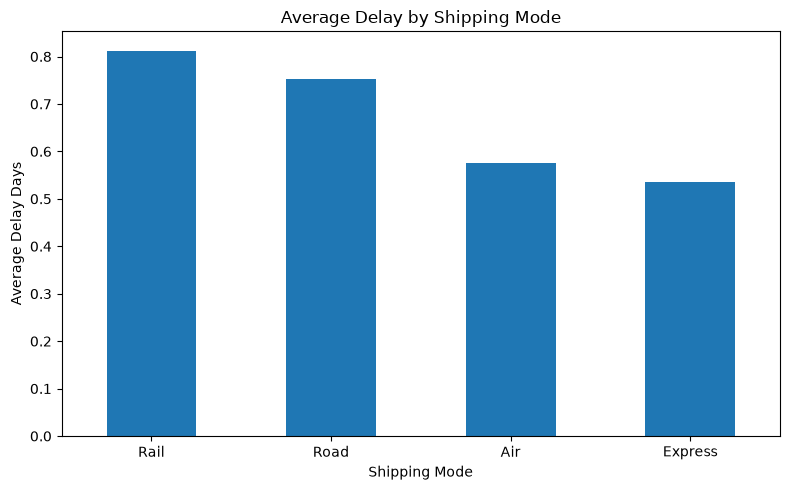

In [20]:
# Visualization of logistics analysis

import matplotlib.pyplot as plt

# 1. Delivery Status
plt.figure(figsize=(7, 5))
status_percentage = df["delivery_status"].value_counts(normalize=True) * 100

status_percentage.plot(kind="bar")

plt.title("Delivery Status Percentage")
plt.xlabel("Delivery Status")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 2. Shipping Mode Count
plt.figure(figsize=(8, 5))
shipping_mode_counts = df["shipping_mode"].value_counts()

shipping_mode_counts.plot(kind="bar")

plt.title("Shipments by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 3. Average Delivery Time by Shipping Mode
plt.figure(figsize=(8, 5))

avg_delivery_by_mode.plot(kind="bar")

plt.title("Average Delivery Time by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 4. Average Shipping Cost by Shipping Mode
plt.figure(figsize=(8, 5))

avg_cost_by_mode.plot(kind="bar")

plt.title("Average Shipping Cost by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Cost")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 5. Average Delay by Shipping Mode
plt.figure(figsize=(8, 5))

avg_delay_by_mode.plot(kind="bar")

plt.title("Average Delay by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Delay Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

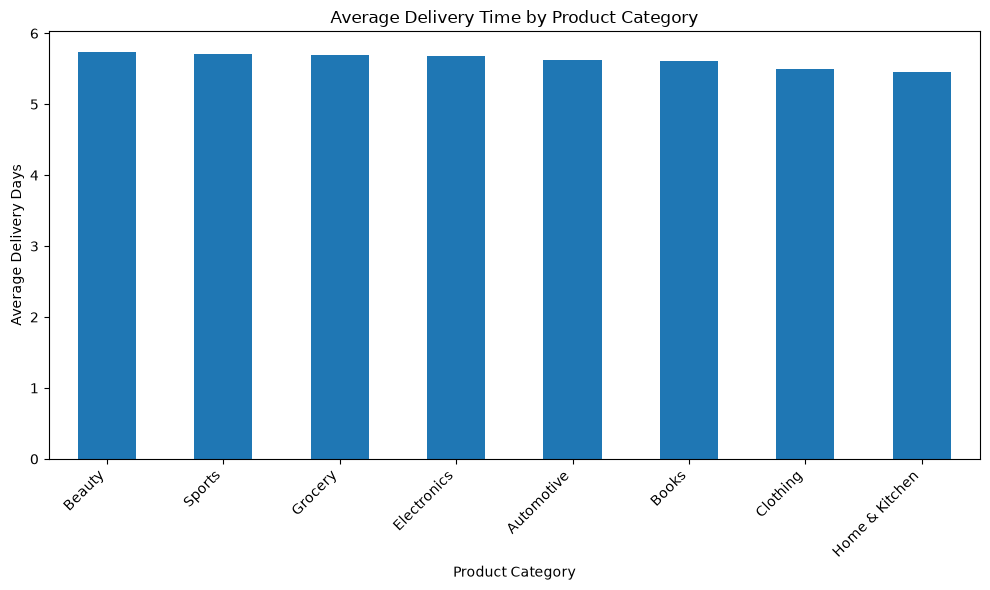

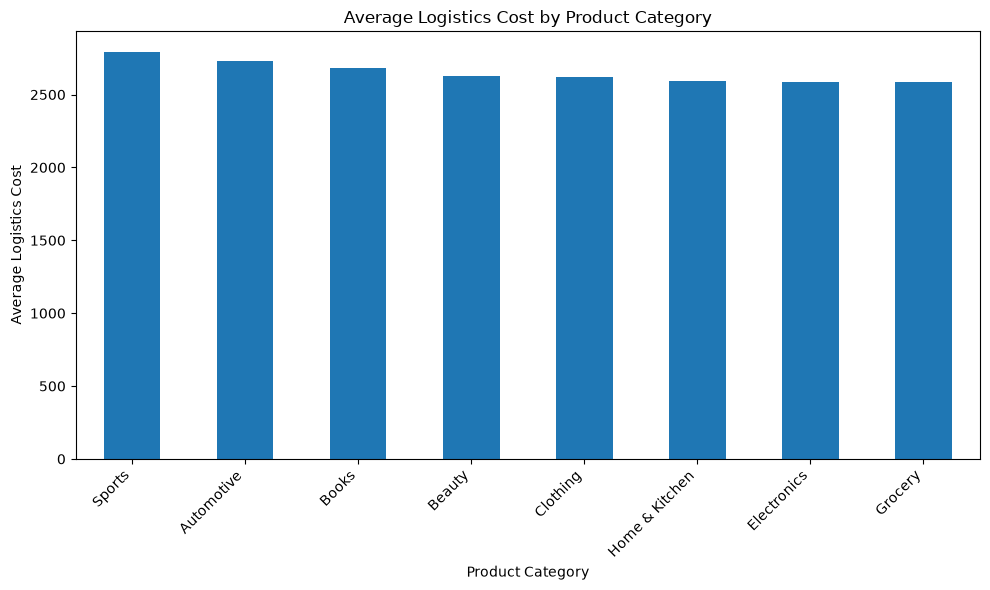

In [21]:
# Product Category Analysis

# Average Delivery Time
plt.figure(figsize=(10, 6))

avg_delivery_by_category.plot(kind="bar")

plt.title("Average Delivery Time by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Average Logistics Cost
plt.figure(figsize=(10, 6))

avg_cost_by_category.plot(kind="bar")

plt.title("Average Logistics Cost by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Logistics Cost")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
# Overall Business KPIs

total_shipments = len(df)

delivered_shipments = (df["delivery_status"] == "Delivered").sum()
delayed_shipments = (df["delivery_status"] == "Delayed").sum()

overall_delivery_rate = (delivered_shipments / total_shipments) * 100
overall_delay_rate = (delayed_shipments / total_shipments) * 100

average_delivery_days = df["delivery_days"].mean()
average_delay_days = df["delay_days"].mean()
average_shipping_cost = df["shipping_cost"].mean()
average_logistics_cost = df["total_logistics_cost"].mean()

print("===== LOGISTICS BUSINESS KPIs =====")
print("Total Shipments:", total_shipments)
print("Delivered Shipments:", delivered_shipments)
print("Delayed Shipments:", delayed_shipments)
print("Delivery Rate: {:.2f}%".format(overall_delivery_rate))
print("Delay Rate: {:.2f}%".format(overall_delay_rate))
print("Average Delivery Days: {:.2f}".format(average_delivery_days))
print("Average Delay Days: {:.2f}".format(average_delay_days))
print("Average Shipping Cost: {:.2f}".format(average_shipping_cost))
print("Average Logistics Cost: {:.2f}".format(average_logistics_cost))

===== LOGISTICS BUSINESS KPIs =====
Total Shipments: 4963
Delivered Shipments: 3775
Delayed Shipments: 1188
Delivery Rate: 76.06%
Delay Rate: 23.94%
Average Delivery Days: 5.63
Average Delay Days: 0.71
Average Shipping Cost: 2281.89
Average Logistics Cost: 2654.34
